# Two SAMap runs compared

Compares the outputs of two runs of this pipeline from the small files each step writes:

- the homology maps: the genes that step 0c renamed to the objects' gene names, for a run that has a
  `0_homology_relabeled/` folder;
- step 2: the alignment scores and within-species metrics (`2_samap/eval.json`) and the mapping scores between human
  and mouse cell types, subtypes and timepoints (`2_samap/mapping_*.csv`);
- step 3: the transfer summaries (`3_transfer/summary.json`) and, nucleus by nucleus, the transferred cell type and
  pseudotime (`3_transfer/transfers.csv`).

It reads no h5ad file. From the repository:

    sbatch record/run_notebook.sbatch samap/notebooks/compare_two_runs.ipynb <folder> \
        -p RUN_A <run folder> -p RUN_B <run folder> -p OUT <folder>

In [1]:
# Parameters; papermill -p NAME VALUE overrides them in a cell below this one.
RUN_A = "/n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_12_xmens_samap_final"
RUN_B = "/n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_13_xmens_samap_relabeled"
LABEL_A = "gene symbols"  # the homology maps as built, genes named by their Ensembl 113 symbols
LABEL_B = "Ensembl IDs"  # the maps with genes renamed to the objects' names, matched by Ensembl ID (step 0c)
OUT = ""  # a folder for comparison.json and switched_nuclei.csv; "" writes nothing

## Inputs

The files read from each run, with their sizes and sha256 checksums (the first 16 characters here; all of them in
`comparison.json`).

In [2]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import pearsonr, spearmanr

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

A, B = LABEL_A, LABEL_B
RUNS = {A: Path(RUN_A), B: Path(RUN_B)}
FILES = ["2_samap/eval.json", "2_samap/mapping_celltype.csv", "2_samap/mapping_subtype.csv",
         "2_samap/mapping_timepoint.csv", "3_transfer/summary.json", "3_transfer/transfers.csv"]


def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 24), b""):
            digest.update(block)
    return digest.hexdigest()


inputs = pd.DataFrame([{"run": label, "file": name, "bytes": (run / name).stat().st_size,
                        "sha256": sha256_of(run / name)}
                       for label, run in RUNS.items() for name in FILES])
for label, run in RUNS.items():
    print(f"{label}: {run}")
display(inputs.assign(sha256=inputs.sha256.str[:16]))

gene symbols: /n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_12_xmens_samap_final
Ensembl IDs: /n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_13_xmens_samap_relabeled


,run,file,bytes,sha256
0,gene symbols,2_samap/eval.json,1693,5874c926cb21f516
1,gene symbols,2_samap/mapping_celltype.csv,361,f1f0665d581659d8
2,gene symbols,2_samap/mapping_subtype.csv,1287,e8d861c27ad635d9
3,gene symbols,2_samap/mapping_timepoint.csv,851,57d86a4e2d1ff7f0
4,gene symbols,3_transfer/summary.json,1153,c913ae831efae8ce
5,gene symbols,3_transfer/transfers.csv,6521506,68c1c0e0552f1fbd
6,Ensembl IDs,2_samap/eval.json,1690,5c244bbe1eeacefa
7,Ensembl IDs,2_samap/mapping_celltype.csv,361,4bef8c4fdd941dbc
8,Ensembl IDs,2_samap/mapping_subtype.csv,1285,0c2c3fde22ec879d
9,Ensembl IDs,2_samap/mapping_timepoint.csv,845,6916437f8c69dcf7


## The homology maps

Step 0c renames genes in the homology maps to the gene names of the objects, matching them by Ensembl gene ID. A run
without a `0_homology_relabeled/` folder used the maps as built. Olfactory receptor genes (`Or...` in the maps,
`Olfr...` in the mouse object) are counted separately.

In [3]:
for label, run in RUNS.items():
    folder = run / "0_homology_relabeled"
    if not folder.exists():
        print(f"{label}: no step 0c; the homology maps as built")
        continue
    renamed = pd.read_csv(folder / "renamed_genes.tsv", sep="\t")
    not_renamed = pd.read_csv(folder / "not_renamed.tsv", sep="\t")
    olfactory = renamed.object_name.str.match(r"Olfr\d")
    counts = pd.DataFrame({"renamed": renamed.groupby("species").size(),
                           "of which olfactory receptors": renamed[olfactory].groupby("species").size(),
                           "left as they were": not_renamed.groupby("species").size()})
    print(f"{label}: genes renamed by step 0c ({folder})")
    display(counts.fillna(0).astype(int))
    print("The first renamed genes other than olfactory receptors, by species:")
    display(renamed[~olfactory].groupby("species").head(8))
    print("Genes left as they were, and why:")
    display(not_renamed)

gene symbols: no step 0c; the homology maps as built
Ensembl IDs: genes renamed by step 0c (/n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_13_xmens_samap_relabeled/0_homology_relabeled)


,renamed,of which olfactory receptors,left as they were
species,,,
human,92,0,0
mouse,2178,1132,13


The first renamed genes other than olfactory receptors, by species:


,species,map_name_ensembl113,object_name
0,human,AFG2A,SPATA5
1,human,AFG2B,SPATA5L1
2,human,AIRIM,C1orf109
3,human,ARB2A,FAM172A
4,human,ARK2C,RNF165
5,human,ARK2N,C18orf25
6,human,ARMCX5-GPRASP2,ARMCX5-GPRASP2-1
7,human,BRD10,KIAA2026
92,mouse,4933416I08Rik,Gm14597
93,mouse,AAdacl4fm3,Gm13178


Genes left as they were, and why:


,species,map_name_ensembl113,object_name,reason
0,mouse,4933427D14Rik,4933427D14Rik;Gm43951,several genes of this name in the object
1,mouse,Ddit3,Ddit3;Ddit3-1,several genes of this name in the object
2,mouse,Dpep2,Dpep2;Dpep2-1,several genes of this name in the object
3,mouse,Fam90a1b,Fam90a1b;Fam90a1b-1,several genes of this name in the object
4,mouse,Lhb,AC151602.1;Lhb,several genes of this name in the object
5,mouse,Nnt,Nnt;Nnt-1,several genes of this name in the object
6,mouse,Nrg1,AC132407.1;Nrg1,several genes of this name in the object
7,mouse,Or5ae1,Olfr290;Olfr290-1,several genes of this name in the object
8,mouse,Pakap,Pakap;Pakap-1,several genes of this name in the object
9,mouse,Ptp4a1,Ptp4a1;Ptp4a1-1,several genes of this name in the object


## Step 2: alignment scores and within-species metrics

Every number in `2_samap/eval.json` except the mapping scores, which are compared below from the CSV files.

In [4]:
def numbers(tree, prefix=""):
    """Every number in a nested JSON object, keyed by its path (a/b/c)."""
    found = {}
    for key, value in tree.items():
        path = f"{prefix}{key}"
        if isinstance(value, dict):
            found.update(numbers(value, path + "/"))
        elif isinstance(value, (int, float)) and not isinstance(value, bool):
            found[path] = value
    return found


def side_by_side(name, skip=()):
    """The numbers in one JSON file of both runs, and B - A."""
    table = pd.DataFrame({label: numbers(json.loads((run / name).read_text())) for label, run in RUNS.items()})
    if skip:
        table = table[~table.index.str.startswith(tuple(skip))]
    table[f"{B} - {A}"] = table[B] - table[A]
    return table


evaluation = side_by_side("2_samap/eval.json", skip=("celltype_mapping", "subtype_mapping", "timepoint_mapping"))
# A species' alignment with itself is 0 by construction.
evaluation = evaluation.drop(index=["alignment/hs/hs", "alignment/mm/mm"], errors="ignore")
display(evaluation.round(4))

,gene symbols,Ensembl IDs,Ensembl IDs - gene symbols
n_cells_joint,89784.0000,89784.0000,0.0000
alignment/hs/mm,0.6835,0.6802,-0.0033
alignment/mm/hs,0.6629,0.6618,-0.0011
mean_alignment,0.6732,0.6710,-0.0022
within_hs/sample_mixing/observed_other_sample_frac,0.6569,0.6568,-0.0000
within_hs/sample_mixing/expected_other_sample_frac,0.8291,0.8291,0.0000
within_hs/sample_mixing/mixing_ratio,0.7923,0.7922,-0.0000
within_hs/sample_mixing/n_samples,6.0000,6.0000,0.0000
within_hs/knn_celltype_agreement,0.8780,0.8780,-0.0000
within_hs/leiden_vs_celltype_ARI,0.0831,0.0887,0.0056


## Step 3: transfer summaries

Every number in `3_transfer/summary.json` except the size of the SAMap object.

In [5]:
summary = side_by_side("3_transfer/summary.json", skip=("samap_final",))
display(summary.round(4))

,gene symbols,Ensembl IDs,Ensembl IDs - gene symbols
human_nuclei,46818.0000,46818.0000,0.0000
cell_type/labelled,46808.0000,46811.0000,3.0000
cell_type/unmapped,10.0000,7.0000,-3.0000
cell_type/ties,0.0000,0.0000,0.0000
cell_type/median_vote_share,1.0000,1.0000,0.0000
cell_type/counts/endometrial_fibroblast,25567.0000,25603.0000,36.0000
cell_type/counts/decidual_cell,21241.0000,21208.0000,-33.0000
cell_type/agree_with_native,34514.0000,34429.0000,-85.0000
cell_type/agree_share_of_labelled,0.7374,0.7355,-0.0019
cell_type/agree_share_of_all,0.7372,0.7354,-0.0018


## Step 3, nucleus by nucleus: the transferred cell type

`unmapped` marks a nucleus with no edge to a mouse nucleus. The vote share is the fraction of a nucleus's edge weight
to mouse that goes to the cell type it receives (0 for an unmapped nucleus); with two cell types it lies between 0.5
and 1, and calls near 0.5 are the uncertain ones.

46,818 human nuclei; the same transferred cell type in both runs: 45,894 (98.03%); a different one: 924


Ensembl IDs,decidual_cell,endometrial_fibroblast,unmapped,All
gene symbols,,,,
decidual_cell,20763,476,2,21241
endometrial_fibroblast,439,25127,1,25567
unmapped,6,0,4,10
All,21208,25603,7,46818


Nuclei whose transferred cell type changed, by their native cell type:


transferred_mouse_fibdec,decidual_cell -> endometrial_fibroblast,decidual_cell -> unmapped,endometrial_fibroblast -> decidual_cell,endometrial_fibroblast -> unmapped,same,unmapped -> decidual_cell,All
native_cell_type,,,,,,,
decidual_cell,306,0,245,0,19090,1,19642
endometrial_fibroblast,170,2,194,1,26804,5,27176
All,476,2,439,1,45894,6,46818


Vote shares of the nuclei whose transferred cell type is the same in both runs, and of those where it differs:


,same: vote share in gene symbols,same: vote share in Ensembl IDs,different: vote share in gene symbols,different: vote share in Ensembl IDs
count,45894.000,45894.000,924.000,924.000
mean,0.946,0.944,0.661,0.661
std,0.100,0.101,0.166,0.164
min,0.000,0.000,0.000,0.000
5%,0.699,0.698,0.503,0.503
25%,0.949,0.948,0.545,0.545
50%,1.000,1.000,0.600,0.600
75%,1.000,1.000,0.748,0.748
max,1.000,1.000,1.000,1.000


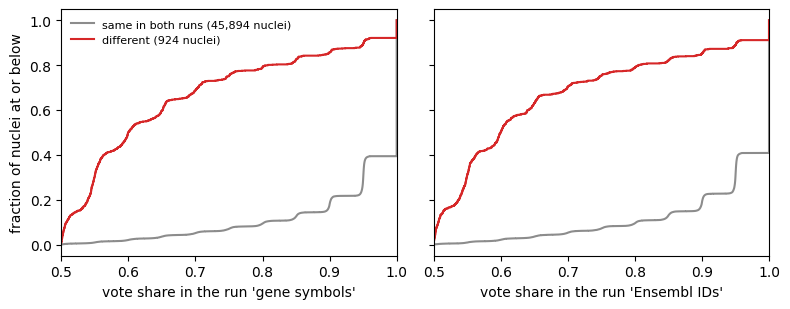

In [6]:
transfers = {label: pd.read_csv(run / "3_transfer/transfers.csv", index_col="cell") for label, run in RUNS.items()}
assert transfers[A].index.equals(transfers[B].index), "the runs hold different human nuclei"
assert transfers[A].native_cell_type.equals(transfers[B].native_cell_type)
native = transfers[A].native_cell_type
identity_a, identity_b = transfers[A].transferred_mouse_fibdec, transfers[B].transferred_mouse_fibdec
same = identity_a == identity_b
print(f"{len(same):,} human nuclei; the same transferred cell type in both runs: {same.sum():,} "
      f"({100 * same.mean():.2f}%); a different one: {(~same).sum():,}")
display(pd.crosstab(identity_a, identity_b, rownames=[A], colnames=[B], margins=True))

print("Nuclei whose transferred cell type changed, by their native cell type:")
direction = (identity_a + " -> " + identity_b).where(~same, "same")
display(pd.crosstab(native, direction, margins=True))

share_a, share_b = transfers[A].fibdec_vote_share, transfers[B].fibdec_vote_share
print("Vote shares of the nuclei whose transferred cell type is the same in both runs, and of those where it differs:")
display(pd.DataFrame({f"{group}: vote share in {label}": shares[mask].describe(percentiles=[0.05, 0.25, 0.5, 0.75])
                      for group, mask in (("same", same), ("different", ~same))
                      for label, shares in ((A, share_a), (B, share_b))}).round(3))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
for ax, (label, shares) in zip(axes, ((A, share_a), (B, share_b))):
    for group, mask, color in (("same in both runs", same, "0.55"), ("different", ~same, "tab:red")):
        values = np.sort(shares[mask].dropna().to_numpy())
        ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post", color=color,
                label=f"{group} ({mask.sum():,} nuclei)")
    ax.set_xlabel(f"vote share in the run '{label}'")
    ax.set_xlim(0.5, 1.0)
axes[0].set_ylabel("fraction of nuclei at or below")
axes[0].legend(frameon=False, loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

## Step 3, nucleus by nucleus: the transferred pseudotime

A nucleus has no transferred pseudotime when none of its mouse neighbors has one; the correlations use the nuclei with
a value in both runs. `pseudotime_weight` is the edge weight behind a nucleus's value.

a value in both runs: 46,375; in 'gene symbols' only: 42; in 'Ensembl IDs' only: 55; in neither: 346
Pearson r 0.9913; Spearman rho 0.9903


,count,mean,std,min,50%,90%,95%,99%,max
|Ensembl IDs - gene symbols|,46375.0,0.0168,0.0269,0.0,0.0103,0.0358,0.05,0.1104,0.8327


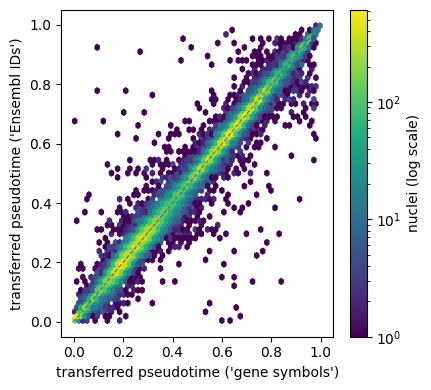

The 10 nuclei whose transferred pseudotime changed most; median weight 13.34 ('gene symbols'), 13.23 ('Ensembl IDs'):


,pseudotime (gene symbols),pseudotime (Ensembl IDs),weight (gene symbols),weight (Ensembl IDs),same cell type
cell,,,,,
ATGCATGAGCGTCGAA-1-secretory_mck6c,0.099,0.932,9.698,2.434,False
CGATGGCCAGTCGTTA-1-menstrual_mck5c,0.845,0.130,0.506,6.883,False
TTTACCAAGCACTCCG-1-menstrual_mck5c,0.096,0.786,11.715,0.100,False
CTTCCTTCATACAGGG-1-menstrual_mck5b,0.007,0.683,19.147,3.625,False
AGTACCACAACCGTAT-1-menstrual_mck5b,0.682,0.020,9.183,11.975,False
GTCATTTGTTGCACGC-1-menstrual_mck5c,0.265,0.911,9.162,16.576,False
GCTCAAATCACATCAG-1-secretory_mck6a,0.628,0.010,5.260,14.509,False
TAACCAGTCACCATCC-1-menstrual_mck5c,0.655,0.044,2.289,8.936,False
CATCGGGGTATGAGAT-1-secretory_mck6b,0.603,0.007,4.389,18.672,False


In [7]:
pt_a, pt_b = transfers[A].transferred_mouse_pseudotime, transfers[B].transferred_mouse_pseudotime
both = pt_a.notna() & pt_b.notna()
difference = (pt_b - pt_a)[both]
pearson = pearsonr(pt_a[both], pt_b[both])[0]
spearman = spearmanr(pt_a[both], pt_b[both]).correlation
print(f"a value in both runs: {both.sum():,}; in '{A}' only: {(pt_a.notna() & pt_b.isna()).sum():,}; "
      f"in '{B}' only: {(pt_a.isna() & pt_b.notna()).sum():,}; in neither: {(pt_a.isna() & pt_b.isna()).sum():,}")
print(f"Pearson r {pearson:.4f}; Spearman rho {spearman:.4f}")
display(difference.abs().describe(percentiles=[0.5, 0.9, 0.95, 0.99]).rename(f"|{B} - {A}|").to_frame().T.round(4))

fig, ax = plt.subplots(figsize=(4.4, 4))
hexes = ax.hexbin(pt_a[both], pt_b[both], gridsize=60, bins="log", mincnt=1, cmap="viridis")
ax.plot([0, 1], [0, 1], color="0.4", linewidth=0.8, linestyle="--")
ax.set_xlabel(f"transferred pseudotime ('{A}')")
ax.set_ylabel(f"transferred pseudotime ('{B}')")
fig.colorbar(hexes, ax=ax, label="nuclei (log scale)")
fig.tight_layout()
plt.show()

print("The 10 nuclei whose transferred pseudotime changed most; median weight "
      f"{transfers[A].pseudotime_weight.median():.2f} ('{A}'), {transfers[B].pseudotime_weight.median():.2f} ('{B}'):")
largest = difference.abs().sort_values(ascending=False).index[:10]
display(pd.DataFrame({f"pseudotime ({A})": pt_a[largest], f"pseudotime ({B})": pt_b[largest],
                      f"weight ({A})": transfers[A].pseudotime_weight[largest],
                      f"weight ({B})": transfers[B].pseudotime_weight[largest],
                      "same cell type": same[largest]}).round(3))

## Step 2: mapping scores

SAMap's mapping scores between human groups (rows) and mouse groups (columns) for cell types, mouse subtypes and
timepoints: each run, the difference, and each group's best match in the other species.

In [8]:
mapping = {}
for kind in ("celltype", "subtype", "timepoint"):
    # Rows and columns name the groups of both species (hs_..., mm_...); the human x mouse block holds the
    # cross-species scores.
    blocks = {}
    for label, run in RUNS.items():
        scores = pd.read_csv(run / f"2_samap/mapping_{kind}.csv", index_col=0)
        blocks[label] = scores.loc[scores.index.str.startswith("hs_"), scores.columns.str.startswith("mm_")]
    change = blocks[B] - blocks[A]
    best_mouse = pd.DataFrame({f"best mouse match ({label})": block.idxmax(axis=1) for label, block in blocks.items()})
    best_human = pd.DataFrame({f"best human match ({label})": block.idxmax(axis=0) for label, block in blocks.items()})
    same_best = bool((best_mouse.nunique(axis=1) == 1).all() and (best_human.nunique(axis=1) == 1).all())
    mapping[kind] = {"max_abs_difference": float(change.abs().to_numpy().max()), "same_best_matches": same_best}
    print(f"== {kind}: largest |{B} - {A}| {mapping[kind]['max_abs_difference']:.4f}; "
          f"the same best match for every group in both runs: {same_best}")
    for title, table in ((A, blocks[A]), (B, blocks[B]), (f"{B} - {A}", change)):
        print(title)
        display(table.round(3))
    display(best_mouse)
    display(best_human)

== celltype: largest |Ensembl IDs - gene symbols| 0.0040; the same best match for every group in both runs: True
gene symbols


,mm_decidual_cell,mm_endometrial_fibroblast
hs_decidual_cell,0.509,0.179
hs_endometrial_fibroblast,0.178,0.610


Ensembl IDs


,mm_decidual_cell,mm_endometrial_fibroblast
hs_decidual_cell,0.505,0.181
hs_endometrial_fibroblast,0.179,0.612


Ensembl IDs - gene symbols


,mm_decidual_cell,mm_endometrial_fibroblast
hs_decidual_cell,-0.004,0.003
hs_endometrial_fibroblast,0.001,0.002


... (14 outputs left out)

Ensembl IDs - gene symbols


,mm_1.5dpi_early,mm_1.5dpi_late,mm_2.5dpi,mm_3.5dpi,mm_4.5dpi_menstrual,mm_uninduced
hs_menstrual,-0.005,0.014,0.006,-0.002,-0.001,-0.006
hs_secretory,0.005,-0.014,-0.006,-0.001,-0.000,0.001


,best mouse match (gene symbols),best mouse match (Ensembl IDs)
hs_menstrual,mm_4.5dpi_menstrual,mm_4.5dpi_menstrual
hs_secretory,mm_uninduced,mm_uninduced


,best human match (gene symbols),best human match (Ensembl IDs)
mm_1.5dpi_early,hs_secretory,hs_secretory
mm_1.5dpi_late,hs_menstrual,hs_menstrual
mm_2.5dpi,hs_menstrual,hs_menstrual
mm_3.5dpi,hs_menstrual,hs_menstrual
mm_4.5dpi_menstrual,hs_menstrual,hs_menstrual
mm_uninduced,hs_secretory,hs_secretory


## Summary

The numbers above that sum up the comparison; with OUT set, they go to `OUT/comparison.json` (with the inputs and
their checksums), and the nuclei whose transferred cell type changed go to `OUT/switched_nuclei.csv`.

In [9]:
quantiles = difference.abs().quantile([0.5, 0.95])
comparison = {
    "runs": {label: str(run) for label, run in RUNS.items()},
    "mean_alignment": {label: float(evaluation.loc["mean_alignment", label]) for label in (A, B)},
    "human_nuclei": int(len(same)),
    "same_transferred_cell_type": int(same.sum()),
    "different_transferred_cell_type": int((~same).sum()),
    "median_vote_share_of_the_different": {label: float(shares[~same].median())
                                           for label, shares in ((A, share_a), (B, share_b))},
    "median_vote_share_of_the_same": {label: float(shares[same].median())
                                      for label, shares in ((A, share_a), (B, share_b))},
    "pseudotime": {"nuclei_with_a_value_in_both": int(both.sum()), "pearson": float(pearson),
                   "spearman": float(spearman), "median_abs_difference": float(quantiles[0.5]),
                   "p95_abs_difference": float(quantiles[0.95]), "max_abs_difference": float(difference.abs().max())},
    "mapping_scores": mapping,
}
print(json.dumps(comparison, indent=1))

if OUT:
    out = Path(OUT)
    out.mkdir(parents=True, exist_ok=True)
    assert not (out / "comparison.json").exists(), f"{out} already holds a comparison"
    record = {**comparison, "inputs": inputs.to_dict(orient="records")}
    (out / "comparison.json").write_text(json.dumps(record, indent=1) + "\n")
    switched = pd.DataFrame({"native_cell_type": native, f"cell_type ({A})": identity_a, f"vote_share ({A})": share_a,
                             f"cell_type ({B})": identity_b, f"vote_share ({B})": share_b})[~same]
    switched.to_csv(out / "switched_nuclei.csv")
    print(f"wrote {out / 'comparison.json'} and {out / 'switched_nuclei.csv'} ({len(switched):,} nuclei)")

{
 "runs": {
  "gene symbols": "/n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_12_xmens_samap_final",
  "Ensembl IDs": "/n/netscratch/eddy_lab/Everyone/nhilgert/2026_11_13_xmens_samap_relabeled"
 },
 "mean_alignment": {
  "gene symbols": 0.6731769968221357,
  "Ensembl IDs": 0.6709843632760287
 },
 "human_nuclei": 46818,
 "same_transferred_cell_type": 45894,
 "different_transferred_cell_type": 924,
 "median_vote_share_of_the_different": {
  "gene symbols": 0.5998386330858655,
  "Ensembl IDs": 0.599857871855245
 },
 "median_vote_share_of_the_same": {
  "gene symbols": 1.0,
  "Ensembl IDs": 1.0
 },
 "pseudotime": {
  "nuclei_with_a_value_in_both": 46375,
  "pearson": 0.9913100670574375,
  "spearman": 0.9903302014557809,
  "median_abs_difference": 0.010264895041282474,
  "p95_abs_difference": 0.04999053541465452,
  "max_abs_difference": 0.8326730619014353
 },
 "mapping_scores": {
  "celltype": {
   "max_abs_difference": 0.004009198305402917,
   "same_best_matches": true
  },
  "subtype":